<a href="https://colab.research.google.com/github/Aigulya0/ml-practice/blob/main/Practice_05_Classification_Threshold.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Все библиотеки успешно подключены!")

Все библиотеки успешно подключены!


In [4]:
data = load_breast_cancer()

df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# 1 = злокачественный, 0 = доброкачественный
df["target"] = (data.target == 0).astype(int)

print("Датасет успешно загружен!")
print("Размер:", df.shape)

display(df.head())


Датасет успешно загружен!
Размер: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [5]:
df.to_csv(
    "/content/breast_cancer.csv",
    index=False
)

print("Файл breast_cancer.csv создан!")

Файл breast_cancer.csv создан!


In [6]:
from google.colab import files

files.download("/content/breast_cancer.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
print("Размер датасета:")
print(df.shape)

print("\nТипы данных:")
print(df.dtypes)

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nРаспределение классов:")
print(df["target"].value_counts())

print("\nОсновная статистика:")
display(df.describe())

Размер датасета:
(569, 31)

Типы данных:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave 

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.372583
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,0.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


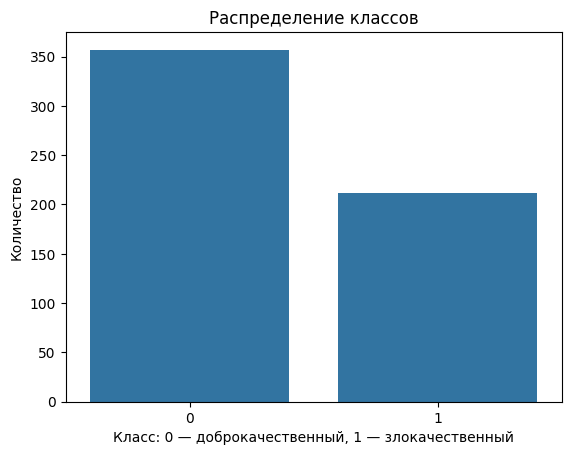

In [8]:
sns.countplot(data=df, x="target")

plt.title("Распределение классов")
plt.xlabel("Класс: 0 — доброкачественный, 1 — злокачественный")
plt.ylabel("Количество")

plt.show()

In [9]:
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (455, 30)
Тестовая выборка: (114, 30)


In [10]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Модель успешно обучена!")

Модель успешно обучена!


In [11]:
y_proba = model.predict_proba(X_test)[:, 1]

print("Первые 10 вероятностей:")
print(np.round(y_proba[:10], 4))

Первые 10 вероятностей:
[4.000e-04 1.000e+00 4.260e-02 5.762e-01 5.092e-01 6.000e-04 7.615e-01
 1.000e-03 6.000e-04 1.080e-02]


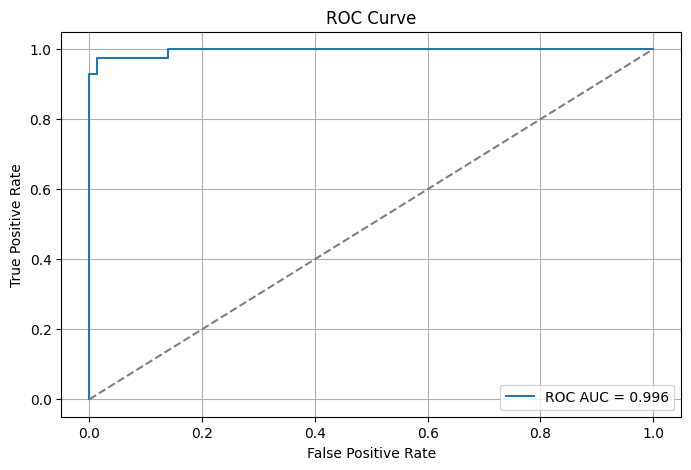

ROC AUC: 0.996


In [12]:
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    y_proba
)

roc_auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC AUC = {roc_auc:.3f}"
)

plt.plot([0, 1], [0, 1], "--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)

plt.savefig("/content/roc_curve.png", dpi=150)
plt.show()

print("ROC AUC:", round(roc_auc, 4))

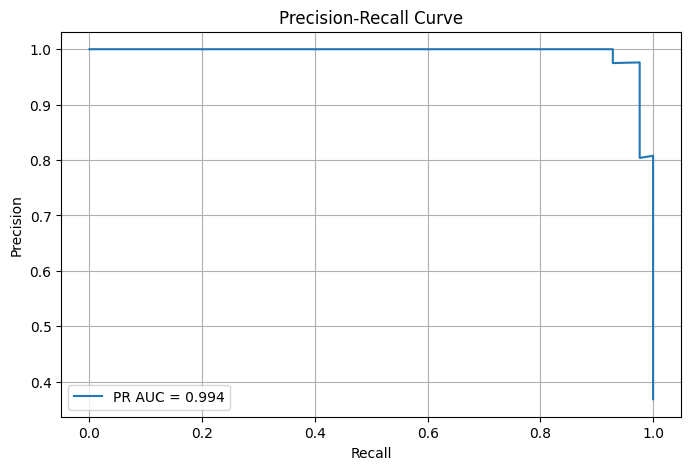

PR AUC: 0.9942
Average Precision: 0.9943


In [13]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_proba
)

pr_auc = np.trapezoid(
    precision[::-1],
    recall[::-1]
)

ap = average_precision_score(y_test, y_proba)

plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label=f"PR AUC = {pr_auc:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True)

plt.savefig("/content/pr_curve.png", dpi=150)
plt.show()

print("PR AUC:", round(pr_auc, 4))
print("Average Precision:", round(ap, 4))

In [14]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

selection_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

selection_model.fit(X_fit, y_fit)

val_proba = selection_model.predict_proba(X_val)[:, 1]

print("Проверочная выборка:", X_val.shape)
print("Вероятности получены!")

Проверочная выборка: (114, 30)
Вероятности получены!


In [15]:
cost_fp = 1
cost_fn = 10

thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)

results = []

for threshold in thresholds:
    predictions = (val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = fp * cost_fp + fn * cost_fn

    results.append({
        "Threshold": threshold,
        "FP": fp,
        "FN": fn,
        "Total Cost": total_cost
    })

cost_df = pd.DataFrame(results)

best_cost = cost_df["Total Cost"].min()

candidates = cost_df[
    (cost_df["Total Cost"] == best_cost) &
    (cost_df["Threshold"] != 0.5)
]

if candidates.empty:
    raise ValueError(
        "Не найден альтернативный порог с минимальной стоимостью."
    )

best_threshold = candidates.iloc[
    (candidates["Threshold"] - 0.5).abs().argmin()
]["Threshold"]

print("Лучший порог:", best_threshold)
print("Минимальная стоимость ошибок:", best_cost)

display(cost_df.sort_values("Total Cost").head(10))

Лучший порог: 0.68
Минимальная стоимость ошибок: 10


,Threshold,FP,FN,Total Cost
80,0.81,0,1,10
81,0.82,0,1,10
82,0.83,0,1,10
79,0.80,0,1,10
75,0.76,0,1,10
78,0.79,0,1,10
77,0.78,0,1,10
91,0.92,0,1,10
87,0.88,0,1,10
86,0.87,0,1,10


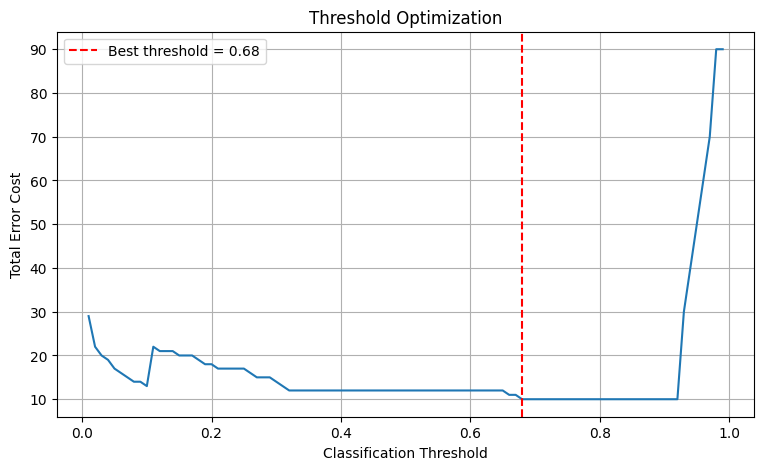

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    cost_df["Threshold"],
    cost_df["Total Cost"]
)

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Best threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Total Error Cost")
plt.title("Threshold Optimization")
plt.legend()
plt.grid(True)

plt.savefig("/content/threshold_cost.png", dpi=150)
plt.show()

In [17]:
# Переобучаем модель на полной обучающей выборке
model.fit(X_train, y_train)

y_proba = model.predict_proba(X_test)[:, 1]

y_pred_default = (y_proba >= 0.5).astype(int)

y_pred_best = (y_proba >= best_threshold).astype(int)

def evaluate_model(y_true, y_pred, threshold):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "FP": fp,
        "FN": fn,
        "Total Cost": fp * cost_fp + fn * cost_fn
    }

comparison = pd.DataFrame([
    evaluate_model(y_test, y_pred_default, 0.5),
    evaluate_model(y_test, y_pred_best, best_threshold)
])

display(comparison.round(4))

,Threshold,Accuracy,Precision,Recall,F1,FP,FN,Total Cost
0,0.50,0.9649,0.975,0.9286,0.9512,1,3,31
1,0.68,0.9649,1.000,0.9048,0.9500,0,4,40


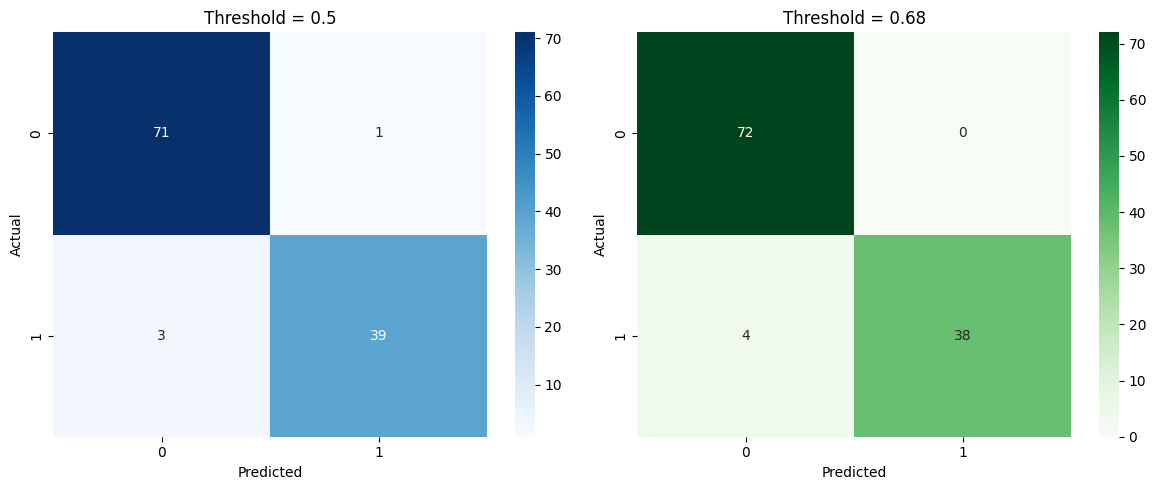

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_default),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Threshold = 0.5")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, y_pred_best),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title(f"Threshold = {best_threshold:.2f}")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("/content/confusion_matrices.png", dpi=150)
plt.show()

In [19]:
default_cost = comparison.iloc[0]["Total Cost"]
optimized_cost = comparison.iloc[1]["Total Cost"]

print("ВЫВОД ПО ПРАКТИЧЕСКОЙ РАБОТЕ №5")
print("-" * 45)

print(f"ROC AUC: {roc_auc_score(y_test, y_proba):.4f}")
print(f"Average Precision: {average_precision_score(y_test, y_proba):.4f}")

print(f"\nСтандартный порог: 0.50")
print(f"Подобранный порог: {best_threshold:.2f}")

print(f"\nСтоимость при 0.5: {default_cost}")
print(f"Стоимость при новом пороге: {optimized_cost}")

if optimized_cost < default_cost:
    print("\nВывод: новый порог снизил стоимость ошибок.")
elif optimized_cost == default_cost:
    print("\nВывод: стоимость ошибок осталась прежней.")
else:
    print("\nВывод: на тестовых данных стоимость ошибок увеличилась.")

print(
    "\nПорог выбран по минимальной условной стоимости "
    "ошибок на проверочной выборке."
)

ВЫВОД ПО ПРАКТИЧЕСКОЙ РАБОТЕ №5
---------------------------------------------
ROC AUC: 0.9960
Average Precision: 0.9943

Стандартный порог: 0.50
Подобранный порог: 0.68

Стоимость при 0.5: 31.0
Стоимость при новом пороге: 40.0

Вывод: на тестовых данных стоимость ошибок увеличилась.

Порог выбран по минимальной условной стоимости ошибок на проверочной выборке.


In [20]:
import os
import sklearn
import matplotlib

os.makedirs("/content/practice_05/results", exist_ok=True)

comparison.to_csv(
    "/content/practice_05/results/metrics_comparison.csv",
    index=False
)

cost_df.to_csv(
    "/content/practice_05/results/threshold_analysis.csv",
    index=False
)

for filename in [
    "roc_curve.png",
    "pr_curve.png",
    "threshold_cost.png",
    "confusion_matrices.png"
]:
    os.replace(
        f"/content/{filename}",
        f"/content/practice_05/results/{filename}"
    )

versions = f"""pandas=={pd.__version__}
numpy=={np.__version__}
matplotlib=={matplotlib.__version__}
seaborn=={sns.__version__}
scikit-learn=={sklearn.__version__}
"""

with open(
    "/content/practice_05/requirements.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(versions)

print("Результаты и requirements.txt сохранены!")

Результаты и requirements.txt сохранены!


In [21]:
readme = f"""# Практическая работа №5

## Тема
Подбор порога бинарной классификации с учётом стоимости ошибок.

## Вариант
Уровень B.

## Цель работы
Обучить модель классификации, получить вероятности классов,
построить ROC- и PR-кривые, подобрать порог классификации
и сравнить результаты с порогом 0.5.

## Датасет
Breast Cancer Wisconsin (Diagnostic).

Источник:
https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

Датасет содержит 569 записей и 30 числовых признаков.

Целевая переменная:
- 0 — доброкачественный случай;
- 1 — злокачественный случай.

## Используемые технологии
- Python
- Google Colab
- pandas
- NumPy
- Matplotlib
- Seaborn
- scikit-learn

## Этапы работы
1. Загрузка и анализ датасета.
2. Разделение данных на обучающую и тестовую выборки.
3. Обучение Logistic Regression.
4. Получение вероятностей через predict_proba.
5. Построение ROC-кривой и PR-кривой.
6. Расчёт ROC AUC и Average Precision.
7. Подбор порога с учётом стоимости ошибок.
8. Сравнение метрик классификации.
9. Анализ матриц ошибок и формулирование вывода.

## Стоимость ошибок
Для учебного эксперимента установлено:
- False Positive (FP) = {cost_fp} балл;
- False Negative (FN) = {cost_fn} баллов.

Эти значения являются учебным допущением.

## Результаты
- ROC AUC: {roc_auc_score(y_test, y_proba):.4f}
- Average Precision: {average_precision_score(y_test, y_proba):.4f}
- Стандартный порог: 0.50
- Подобранный порог: {best_threshold:.2f}
- Стоимость ошибок при 0.5: {default_cost}
- Стоимость ошибок при новом пороге: {optimized_cost}

## Вывод
Модель Logistic Regression была обучена для бинарной
классификации. Получены вероятности положительного класса,
построены ROC- и PR-кривые.

Порог классификации подобран на проверочной выборке
по минимальной условной стоимости ошибок.

На тестовой выборке стоимость ошибок при стандартном пороге
составила {default_cost}, при подобранном — {optimized_cost}.

Выбор порога необходимо оценивать с учётом цены ошибок,
а не только по Accuracy.

## Ограничения
Это учебный эксперимент. Модель не предназначена для
реальной медицинской диагностики.

## Запуск
1. Открыть файл notebooks/Practice_05_Classification_Threshold.ipynb.
2. Запустить ноутбук в Google Colab.
3. Выполнить все ячейки сверху вниз.

## Структура проекта
- data/ — исходный CSV.
- notebooks/ — ноутбук Google Colab.
- results/ — графики и таблицы результатов.
- requirements.txt — версии библиотек.
- README.md — описание практической работы.
"""

with open(
    "/content/practice_05/README.md",
    "w",
    encoding="utf-8"
) as f:
    f.write(readme)

print("README.md успешно создан!")

README.md успешно создан!


In [23]:
import shutil

os.makedirs("/content/practice_05/data", exist_ok=True)

shutil.copy(
    "/content/breast_cancer.csv",
    "/content/practice_05/data/breast_cancer.csv"
)

shutil.make_archive(
    "/content/practice_05",
    "zip",
    "/content/practice_05"
)

from google.colab import files
files.download("/content/practice_05.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>